<a href="https://colab.research.google.com/github/alyPoint/CEFET---Processamento-de-Sinais-I-140826/blob/main/Pratica_7/DSP_1_PRATICA_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Questão 1

Questão 2

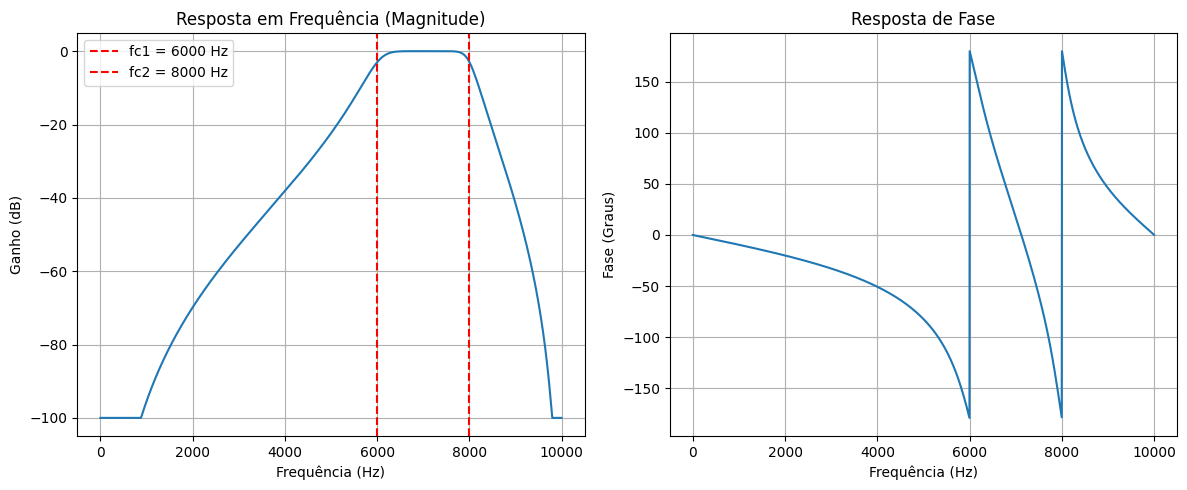

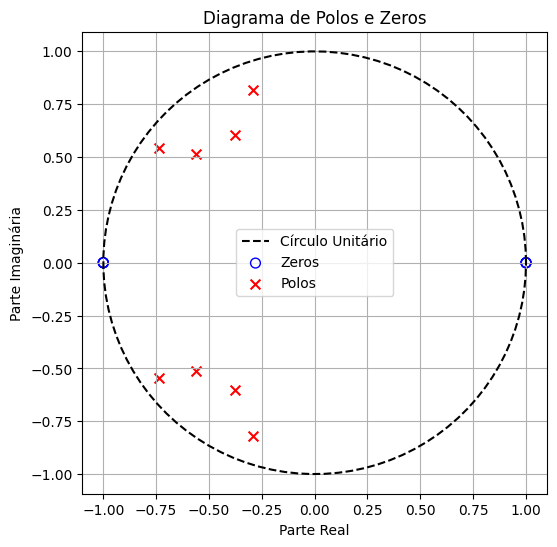

'\nComentários sobre os resultados:\n\n1. Resposta em Frequência:\n   O filtro projetado apresenta uma banda de passagem bem definida entre 6000 Hz e 8000 Hz. \n   A atenuação nas bandas de rejeição é acentuada devido à ordem escolhida.\n\n2. Diagrama de Polos e Zeros:\n   - Os polos estão localizados dentro do círculo unitário, garantindo a estabilidade do filtro digital.\n   - Como a estrutura foi implementada em cascata de blocos de 2ª ordem (SOS - Second Order Sections), \n     ela apresenta maior robustez contra erros de quantização de coeficientes em comparação com a forma direta.\n\n3. Comparação com a Questão 1:\n   - Se na Questão 1 o filtro foi projetado usando uma estrutura de forma direta (IIR de ordem elevada) \n     ou uma topologia FIR, o uso de blocos SOS (2ª ordem) nesta questão proporciona melhor \n     estabilidade numérica e menor sensibilidade ao ruído de arredondamento de ponto fixo/flutuante.\n   - A resposta de fase na banda de passagem de um filtro IIR em casca

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Parâmetros do filtro
fs = 20000.0  # Frequência de amostragem (Hz)
fc1 = 6000.0  # Frequência de corte inferior (Hz)
fc2 = 8000.0  # Frequência de corte superior (Hz)
nyq = 0.5 * fs

# Normalização das frequências de corte
low = fc1 / nyq
high = fc2 / nyq

# Projeto do filtro Butterworth de ordem 4 (resultando em cascata de blocos de 2ª ordem)
# Usamos a representação SOS (Second-Order Sections) para a cascata de 2ª ordem
order = 4
sos = signal.butter(order, [low, high], btype='band', output='sos')

# 1. Resposta em Frequência
w, h = signal.sosfreqz(sos, worN=2000, fs=fs)

plt.figure(figsize=(12, 5))

# Gráfico da Magnitude
plt.subplot(1, 2, 1)
plt.plot(w, 20 * np.log10(np.maximum(abs(h), 1e-5)))
plt.title('Resposta em Frequência (Magnitude)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Ganho (dB)')
plt.grid(True)
plt.axvline(fc1, color='red', linestyle='--', label='fc1 = 6000 Hz')
plt.axvline(fc2, color='red', linestyle='--', label='fc2 = 8000 Hz')
plt.legend()

# Gráfico da Fase
plt.subplot(1, 2, 2)
plt.plot(w, np.angle(h) * 180 / np.pi)
plt.title('Resposta de Fase')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Fase (Graus)')
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Diagramas de Polos e Zeros
# Extração de polos e zeros a partir de SOS
z, p, k = signal.sos2zpk(sos)

plt.figure(figsize=(6, 6))
# Círculo unitário
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo Unitário')

# Plot de polos (x) e zeros (o)
plt.scatter(np.real(z), np.imag(z), s=50, marker='o', facecolors='none', edgecolors='b', label='Zeros')
plt.scatter(np.real(p), np.imag(p), s=50, marker='x', color='r', label='Polos')

plt.title('Diagrama de Polos e Zeros')
plt.xlabel('Parte Real')
plt.ylabel('Parte Imaginária')
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()

# --- COMENTÁRIOS E COMPARAÇÃO ---
"""
Comentários sobre os resultados:

1. Resposta em Frequência:
   O filtro projetado apresenta uma banda de passagem bem definida entre 6000 Hz e 8000 Hz.
   A atenuação nas bandas de rejeição é acentuada devido à ordem escolhida.

2. Diagrama de Polos e Zeros:
   - Os polos estão localizados dentro do círculo unitário, garantindo a estabilidade do filtro digital.
   - Como a estrutura foi implementada em cascata de blocos de 2ª ordem (SOS - Second Order Sections),
     ela apresenta maior robustez contra erros de quantização de coeficientes em comparação com a forma direta.

3. Comparação com a Questão 1:
   - Se na Questão 1 o filtro foi projetado usando uma estrutura de forma direta (IIR de ordem elevada)
     ou uma topologia FIR, o uso de blocos SOS (2ª ordem) nesta questão proporciona melhor
     estabilidade numérica e menor sensibilidade ao ruído de arredondamento de ponto fixo/flutuante.
   - A resposta de fase na banda de passagem de um filtro IIR em cascata tende a ser não-linear,
     o que é característico desse tipo de aproximação se comparado a filtros FIR de fase linear.
"""

Questão 3

Questão 4

Questão 5